# Exploratory Data Analysis (EDA)
## Mumbai Air Quality

In [41]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set(style="whitegrid")

df = pd.read_csv("../data/processed/mumbai_aqi_daily.csv")
df["date"] = pd.to_datetime(df["date"])
df = df.sort_values("date")

df.head()

,date,pm25,pm10,aqi,aqi_bucket
0,2015-01-01,NaN,NaN,NaN,NaN
1,2015-01-02,NaN,NaN,NaN,NaN
2,2015-01-03,NaN,NaN,NaN,NaN
3,2015-01-04,NaN,NaN,NaN,NaN
4,2015-01-05,NaN,NaN,NaN,NaN


Plot 1 — AQI Trend Over Time (MOST IMPORTANT)

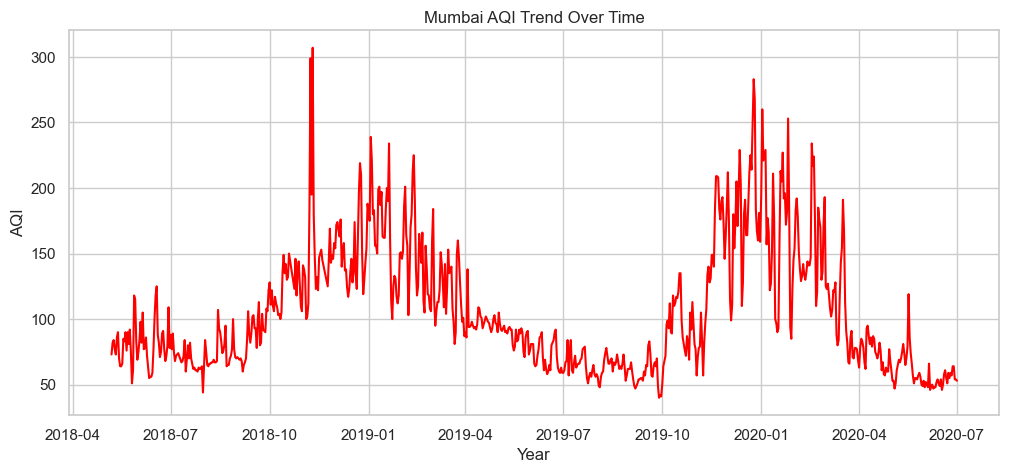

In [42]:
plt.figure(figsize=(12,5))
plt.plot(df["date"], df["aqi"], color="red")
plt.title("Mumbai AQI Trend Over Time")
plt.xlabel("Year")
plt.ylabel("AQI")
plt.show()

What to observe
	•	Long-term fluctuations
	•	High peaks during certain periods
	•	Overall air quality severity

✍️ Insight: AQI shows strong temporal variability with recurring high-pollution periods.

Plot 2 — PM2.5 vs PM10 Trends

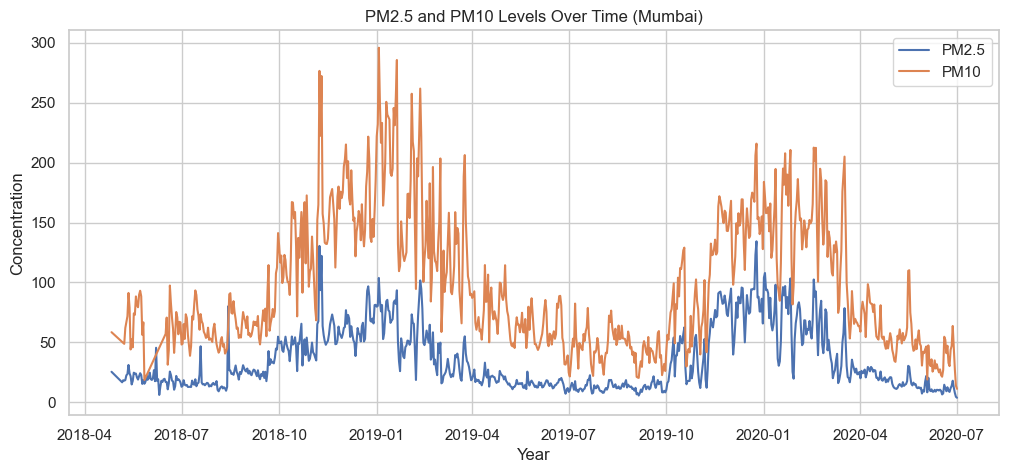

In [43]:
plt.figure(figsize=(12,5))
plt.plot(df["date"], df["pm25"], label="PM2.5")
plt.plot(df["date"], df["pm10"], label="PM10")
plt.legend()
plt.title("PM2.5 and PM10 Levels Over Time (Mumbai)")
plt.xlabel("Year")
plt.ylabel("Concentration")
plt.show()


What to observe
	•	PM2.5 fluctuates more sharply
	•	PM10 generally stays higher but smoother

✍️ Insight: PM2.5 exhibits stronger variability and drives AQI more strongly.


Plot 3 — AQI Category Distribution (Health View)

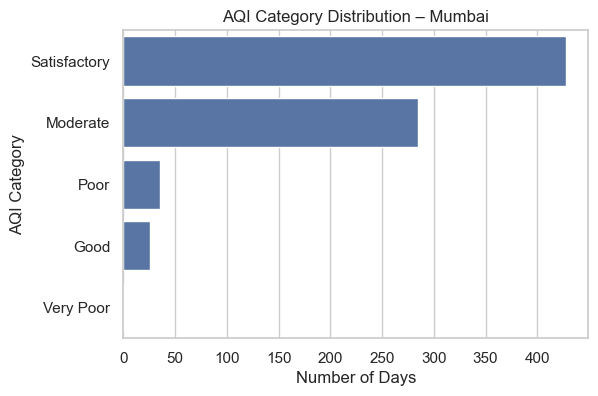

In [44]:
plt.figure(figsize=(6,4))
sns.countplot(y=df["aqi_bucket"],
              order=df["aqi_bucket"].value_counts().index)
plt.title("AQI Category Distribution – Mumbai")
plt.xlabel("Number of Days")
plt.ylabel("AQI Category")
plt.show()

What to observe
	•	Frequency of “Poor”, “Very Poor”, “Severe” days

✍️ Insight: A significant number of days fall under unhealthy AQI categories, posing health risks.

Plot 4 — Correlation Heatmap


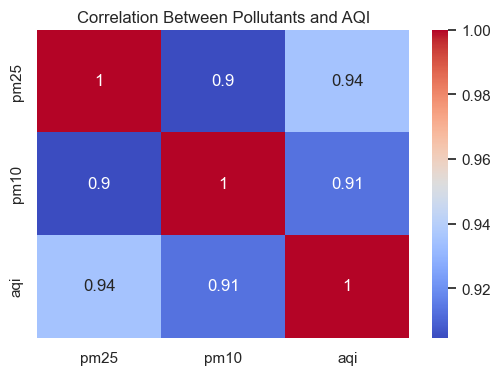

In [45]:
plt.figure(figsize=(6,4))
sns.heatmap(df[["pm25", "pm10", "aqi"]].corr(),
            annot=True,
            cmap="coolwarm")
plt.title("Correlation Between Pollutants and AQI")
plt.show()


What to observe
	•	PM2.5 has highest correlation with AQI

✍️ Insight: PM2.5 is the dominant pollutant influencing AQI

Plot 5 — Monthly AQI Seasonality


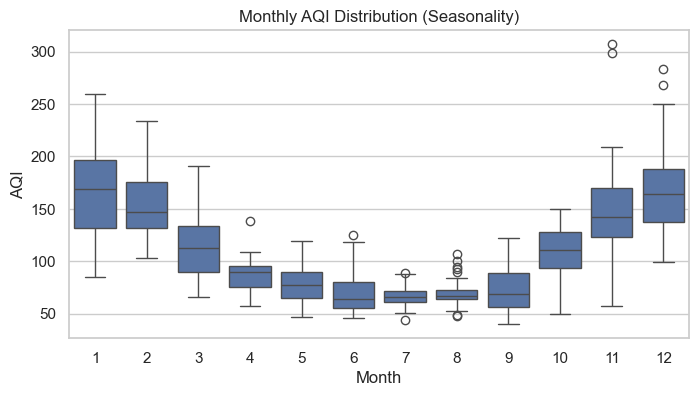

In [46]:
df["month"] = df["date"].dt.month

plt.figure(figsize=(8,4))
sns.boxplot(x="month", y="aqi", data=df)
plt.title("Monthly AQI Distribution (Seasonality)")
plt.xlabel("Month")
plt.ylabel("AQI")
plt.show()

What to observe
	•	Higher AQI in winter months
	•	Cleaner air during monsoon

✍️ Insight: Strong seasonal dependence exists in Mumbai AQI.

Plot 6 — AQI Distribution (Histogram)

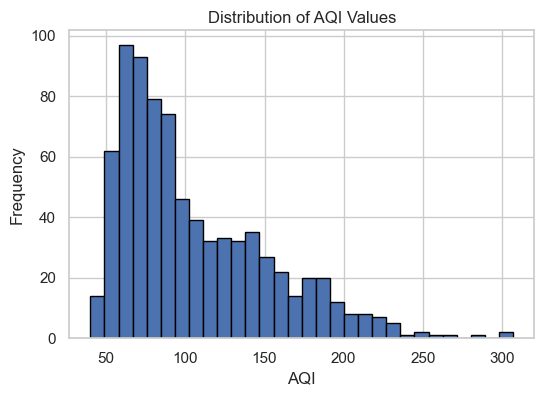

In [47]:
plt.figure(figsize=(6,4))
plt.hist(df["aqi"], bins=30, edgecolor="black")
plt.title("Distribution of AQI Values")
plt.xlabel("AQI")
plt.ylabel("Frequency")
plt.show()

What to observe
	•	Skewness
	•	Presence of extreme AQI values

✍️ Insight: AQI distribution is right-skewed with extreme pollution events.

### Key EDA Insights
- Mumbai AQI shows strong seasonal variation.
- PM2.5 has the highest correlation with AQI.
- Winter months exhibit higher pollution levels.
- A significant number of days fall under unhealthy AQI categories.
